# Day 11 — Date Coverage and Missing Reporting Periods

## Objective
Evaluate the completeness and continuity of the `Order Date` and `Ship Date` fields in the cleaned Superstore dataset.

The analysis identifies missing or invalid date values, dates without recorded activity, reporting periods without activity, and partial calendar-boundary months.

## Scope and interpretation
- The unit counted in daily and reporting-period coverage is a dataset row, not necessarily a distinct order.
- Unique orders are reported separately.
- A calendar date with zero recorded rows is an inactive date, not automatically evidence of missing data.
- A reporting period is considered covered when at least one row exists within it.
- Partial first and last months are flagged because the observed date range does not span the complete calendar month.
- This analysis does not establish whether the dataset contains every real-world transaction.

## 1. Load libraries and define project paths

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / "data" / "processed" / "cleaned_superstore.csv").exists():
    ROOT = Path.cwd().parent

INPUT_FILE = ROOT / "data" / "processed" / "cleaned_superstore.csv"
OUTPUT_DIR = ROOT / "Week3_Trend_Analysis_Business_Insights" / "visualizations"

DATE_COLUMNS = ["Order Date", "Ship Date"]

assert INPUT_FILE.exists(), f"Dataset not found: {INPUT_FILE}"
assert OUTPUT_DIR.exists(), f"Output directory not found: {OUTPUT_DIR}"

print("Project root:", ROOT)
print("Input dataset:", INPUT_FILE)
print("Output directory:", OUTPUT_DIR)

Project root: /Users/hemanth/Sales-Business-Performance-Analytics-Dashboard
Input dataset: /Users/hemanth/Sales-Business-Performance-Analytics-Dashboard/data/processed/cleaned_superstore.csv
Output directory: /Users/hemanth/Sales-Business-Performance-Analytics-Dashboard/Week3_Trend_Analysis_Business_Insights/visualizations


## 2. Load the cleaned dataset and inspect its structure

The raw date strings are retained separately before conversion. This makes it possible to distinguish blank values from nonblank values that cannot be parsed as dates.

In [2]:
df = pd.read_csv(INPUT_FILE, dtype={"Postal Code": "string"})

required_columns = ["Order ID", *DATE_COLUMNS]
missing_columns = [col for col in required_columns if col not in df.columns]
assert not missing_columns, f"Required columns missing: {missing_columns}"

raw_dates = {}
for col in DATE_COLUMNS:
    raw_dates[col] = df[col].copy()
    df[col] = pd.to_datetime(df[col], format="%Y-%m-%d", errors="coerce")

print("Rows:", len(df))
print("Original dataset columns:", len(df.columns))
print("Unique orders:", df["Order ID"].nunique())
print("Order date range:", df["Order Date"].min(), "to", df["Order Date"].max())
print("Ship date range:", df["Ship Date"].min(), "to", df["Ship Date"].max())

for col in DATE_COLUMNS:
    print(f"\\n{col} date statistics:")
    print("Minimum:", df[col].min())
    print("Maximum:", df[col].max())
    print("Distinct dates:", df[col].nunique())

Rows: 10194
Original dataset columns: 21
Unique orders: 5111
Order date range: 2023-01-03 00:00:00 to 2026-12-30 00:00:00
Ship date range: 2023-01-07 00:00:00 to 2027-01-05 00:00:00
\nOrder Date date statistics:
Minimum: 2023-01-03 00:00:00
Maximum: 2026-12-30 00:00:00
Distinct dates: 1242
\nShip Date date statistics:
Minimum: 2023-01-07 00:00:00
Maximum: 2027-01-05 00:00:00
Distinct dates: 1338


## 3. Validate missing and invalid date values

A missing date is a null or blank source value. An invalid date is a nonblank source value that cannot be parsed using the expected `YYYY-MM-DD` format.

In [3]:
date_validation = []

for col in DATE_COLUMNS:
    raw = raw_dates[col]
    blank = raw.isna() | raw.astype("string").str.strip().eq("").fillna(False)
    invalid = (~blank) & df[col].isna()

    date_validation.append({
        "date_column": col,
        "total_rows": len(df),
        "missing_values": int(blank.sum()),
        "invalid_values": int(invalid.sum()),
        "valid_values": int(df[col].notna().sum()),
        "minimum_date": df[col].min(),
        "maximum_date": df[col].max(),
        "distinct_active_dates": int(df[col].dropna().dt.normalize().nunique()),
    })

date_validation_df = pd.DataFrame(date_validation)
display(date_validation_df)

assert (date_validation_df["missing_values"] == 0).all()
assert (date_validation_df["invalid_values"] == 0).all()
assert (date_validation_df["valid_values"] == len(df)).all()
print("PASS: Both date columns contain no missing or invalid values.")

,date_column,total_rows,missing_values,invalid_values,valid_values,minimum_date,maximum_date,distinct_active_dates
0,Order Date,10194,0,0,10194,2023-01-03,2026-12-30,1242
1,Ship Date,10194,0,0,10194,2023-01-07,2027-01-05,1338


PASS: Both date columns contain no missing or invalid values.


## 4. Daily date coverage

For each date column, construct a continuous daily calendar between the minimum and maximum valid dates. Compare this calendar with the dates present in the dataset.

Zero-row dates are labelled as dates without recorded activity.

In [4]:
daily_results = []

for col in DATE_COLUMNS:
    valid_dates = df[col].dropna().dt.normalize()
    counts = valid_dates.value_counts().sort_index()

    calendar = pd.date_range(valid_dates.min(), valid_dates.max(), freq="D")
    coverage = counts.reindex(calendar, fill_value=0)

    daily_results.append(pd.DataFrame({
        "date_column": col,
        "date": calendar,
        "row_count": coverage.to_numpy(),
        "has_activity": coverage.to_numpy() > 0,
    }))

daily_coverage = pd.concat(daily_results, ignore_index=True)

daily_summary = (
    daily_coverage.groupby("date_column")
    .agg(
        calendar_days=("date", "size"),
        active_days=("has_activity", "sum"),
        inactive_days=("has_activity", lambda x: int((~x).sum())),
    )
    .reset_index()
)

display(daily_summary)

,date_column,calendar_days,active_days,inactive_days
0,Order Date,1458,1242,216
1,Ship Date,1460,1338,122


## 5. Identify dates without recorded activity

These dates are useful for understanding activity patterns. They must not be described as missing transactions without an independent expected-activity calendar or source-system evidence.

In [5]:
inactive_dates = daily_coverage[~daily_coverage["has_activity"]].copy()

print("Total inactive date-field observations:", len(inactive_dates))
display(
    inactive_dates.groupby("date_column")
    .size()
    .rename("inactive_days")
    .reset_index()
)

display(inactive_dates.head(20))

Total inactive date-field observations: 338


,date_column,inactive_days
0,Order Date,216
1,Ship Date,122


,date_column,date,row_count,has_activity
5,Order Date,2023-01-08,0,False
9,Order Date,2023-01-12,0,False
14,Order Date,2023-01-17,0,False
19,Order Date,2023-01-22,0,False
21,Order Date,2023-01-24,0,False
22,Order Date,2023-01-25,0,False
26,Order Date,2023-01-29,0,False
33,Order Date,2023-02-05,0,False
37,Order Date,2023-02-09,0,False
38,Order Date,2023-02-10,0,False


## 6. Monthly, quarterly, and yearly reporting-period coverage

Each reporting period between the first and last observed period is included, even if its count is zero. The period is considered covered if at least one dataset row is present.

In [6]:
period_frequencies = {
    "monthly": "M",
    "quarterly": "Q",
    "yearly": "Y",
}

period_results = []

for col in DATE_COLUMNS:
    valid = df[col].dropna()
    period_values = valid.dt.to_period("D")

    for period_name, frequency in period_frequencies.items():
        values = valid.dt.to_period(frequency)
        counts = values.value_counts().sort_index()

        calendar = pd.period_range(values.min(), values.max(), freq=frequency)
        complete = counts.reindex(calendar, fill_value=0)

        first_period = values.min()
        last_period = values.max()

        period_results.append(pd.DataFrame({
            "date_column": col,
            "period_type": period_name,
            "period": complete.index.astype(str),
            "row_count": complete.to_numpy(),
            "has_activity": complete.to_numpy() > 0,
            "boundary_period": [
                str(p) in {str(first_period), str(last_period)}
                for p in complete.index
            ],
        }))

period_coverage = pd.concat(period_results, ignore_index=True)

period_summary = (
    period_coverage.groupby(["date_column", "period_type"])
    .agg(
        periods_in_range=("period", "size"),
        periods_with_activity=("has_activity", "sum"),
        periods_without_activity=("has_activity", lambda x: int((~x).sum())),
    )
    .reset_index()
)

display(period_summary)

,date_column,period_type,periods_in_range,periods_with_activity,periods_without_activity
0,Order Date,monthly,48,48,0
1,Order Date,quarterly,16,16,0
2,Order Date,yearly,4,4,0
3,Ship Date,monthly,49,49,0
4,Ship Date,quarterly,17,17,0
5,Ship Date,yearly,5,5,0


## 7. Check for missing reporting periods

This check focuses on monthly, quarterly, and yearly periods. Daily inactive dates are deliberately excluded from this reporting-period test.

In [7]:
missing_reporting_periods = period_coverage[
    ~period_coverage["has_activity"]
].copy()

if missing_reporting_periods.empty:
    print("PASS: Every monthly, quarterly, and yearly period has recorded activity.")
else:
    display(missing_reporting_periods)

assert missing_reporting_periods.empty, "One or more reporting periods have no activity."

PASS: Every monthly, quarterly, and yearly period has recorded activity.


## 8. Partial first and last months

The first and last observed months may not cover every calendar day. This is a boundary effect and does not by itself indicate missing records.

In [8]:
boundary_results = []

for col in DATE_COLUMNS:
    valid = df[col].dropna()
    first_date = valid.min().normalize()
    last_date = valid.max().normalize()
    first_month = first_date.to_period("M")
    last_month = last_date.to_period("M")

    boundary_results.append({
        "date_column": col,
        "first_month": str(first_month),
        "first_observed_date": first_date.date().isoformat(),
        "first_month_calendar_start": first_month.start_time.date().isoformat(),
        "first_month_partial": first_date > first_month.start_time.normalize(),
        "last_month": str(last_month),
        "last_observed_date": last_date.date().isoformat(),
        "last_month_calendar_end": last_month.end_time.date().isoformat(),
        "last_month_partial": last_date < last_month.end_time.normalize(),
    })

boundary_df = pd.DataFrame(boundary_results)
display(boundary_df)

,date_column,first_month,first_observed_date,first_month_calendar_start,first_month_partial,last_month,last_observed_date,last_month_calendar_end,last_month_partial
0,Order Date,2023-01,2023-01-03,2023-01-01,True,2026-12,2026-12-30,2026-12-31,True
1,Ship Date,2023-01,2023-01-07,2023-01-01,True,2027-01,2027-01-05,2027-01-31,True


## 9. Monthly activity comparison

The chart compares row counts grouped by Order Date and Ship Date. These counts represent dataset records, not distinct orders.

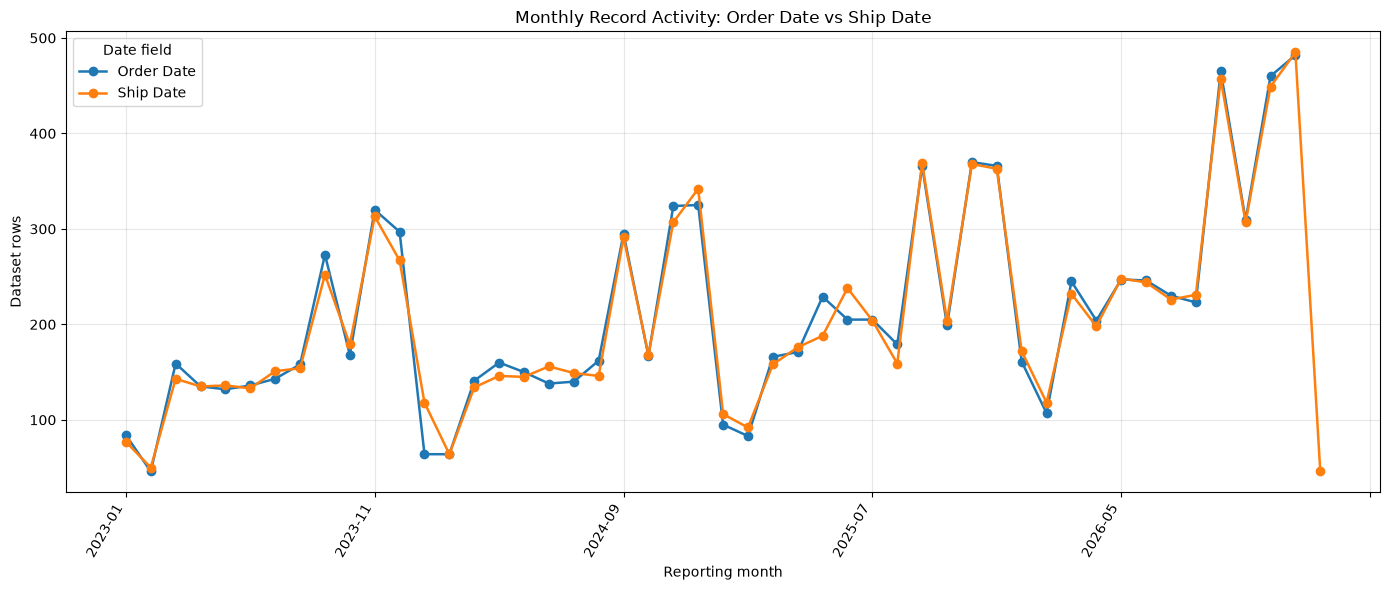

In [9]:
monthly = period_coverage[period_coverage["period_type"] == "monthly"].copy()
monthly_pivot = monthly.pivot(
    index="period",
    columns="date_column",
    values="row_count",
)

ax = monthly_pivot.plot(
    kind="line",
    marker="o",
    figsize=(14, 6),
    linewidth=1.8,
)
ax.set_title("Monthly Record Activity: Order Date vs Ship Date")
ax.set_xlabel("Reporting month")
ax.set_ylabel("Dataset rows")
ax.grid(True, alpha=0.3)
ax.legend(title="Date field")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

## 10. Compare notebook results with the reproducible script outputs

The script-generated CSV files are used as a cross-check to ensure that the notebook's calculations agree with the automated analysis.

In [10]:
script_daily = pd.read_csv(OUTPUT_DIR / "Day_11_Daily_Date_Coverage.csv")
script_periods = pd.read_csv(OUTPUT_DIR / "Day_11_Reporting_Period_Coverage.csv")
script_summary = pd.read_csv(OUTPUT_DIR / "Day_11_Date_Coverage_Summary.csv")

assert len(script_daily) == len(daily_coverage)

script_reporting_periods = script_periods[
    script_periods["period_type"].isin(["monthly", "quarterly", "yearly"])
].copy()

assert len(script_reporting_periods) == len(period_coverage)

for col in DATE_COLUMNS:
    notebook_inactive = int(
        ((daily_coverage["date_column"] == col) & (~daily_coverage["has_activity"])).sum()
    )
    script_inactive = int(
        ((script_daily["date_column"] == col) & (~script_daily["has_activity"])).sum()
    )
    assert notebook_inactive == script_inactive

print("PASS: Notebook daily coverage agrees with the script output.")
print("Daily coverage rows:", len(script_daily))
print("Reporting-period rows (monthly/quarterly/yearly):", len(script_reporting_periods))
display(script_summary)

PASS: Notebook daily coverage agrees with the script output.
Daily coverage rows: 2918
Reporting-period rows (monthly/quarterly/yearly): 139


,date_column,total_rows,missing_date_values,invalid_or_unparseable_dates,minimum_date,maximum_date,distinct_active_dates,calendar_days_in_range,days_with_activity,days_without_activity,...,yearly_periods_with_activity,yearly_periods_without_activity,first_month,first_month_first_observed_date,first_month_calendar_start,first_month_partial_observation,last_month,last_month_last_observed_date,last_month_calendar_end,last_month_partial_observation
0,Order Date,10194,0,0,2023-01-03,2026-12-30,1242,1458,1242,216,...,4,0,2023-01,2023-01-03,2023-01-01,True,2026-12,2026-12-30,2026-12-31,True
1,Ship Date,10194,0,0,2023-01-07,2027-01-05,1338,1460,1338,122,...,5,0,2023-01,2023-01-07,2023-01-01,True,2027-01,2027-01-05,2027-01-31,True


## 11. Key findings

1. Both date columns contain 10,194 valid values, with no missing or invalid date entries.
2. Order Date spans 2023-01-03 through 2026-12-30; Ship Date spans 2023-01-07 through 2027-01-05.
3. There are 216 Order Date inactive calendar days and 122 Ship Date inactive calendar days within their respective observed ranges.
4. Every monthly, quarterly, and yearly reporting period in both observed ranges contains at least one row.
5. The first and last observed months are partial for both date fields.
6. Zero activity on an individual date is not sufficient evidence of missing data.

## 12. Limitations

- The dataset does not provide an independent expected transaction calendar.
- The analysis measures recorded rows and cannot prove that every real-world order or shipment is present.
- The first and last periods are bounded by the minimum and maximum observed dates.
- Order Date and Ship Date are different business events; their daily activity patterns should not be expected to match exactly.
- Counts in this notebook are row counts unless explicitly labelled as unique orders.

## 13. Conclusion

The cleaned dataset has complete, parseable Order Date and Ship Date values. Monthly, quarterly, and yearly reporting-period continuity is present throughout both observed date ranges. Some individual calendar dates have no recorded activity, and the boundary months are partial. These observations should be treated as activity and coverage characteristics rather than proof of missing data.